In [2]:
from google.colab import files
import zipfile
import os

uploaded = files.upload()

for filename in uploaded:
    folder = f"/content/{os.path.splitext(filename)[0]}"
    with zipfile.ZipFile(filename, 'r') as zip_ref:
        zip_ref.extractall(folder)
    print(f"Extracted {filename} to {folder}")


Saving clean_dataset.zip to clean_dataset.zip
Saving Training_video_2.zip to Training_video_2.zip
Saving Training_video_3.zip to Training_video_3.zip
Extracted clean_dataset.zip to /content/clean_dataset
Extracted Training_video_2.zip to /content/Training_video_2
Extracted Training_video_3.zip to /content/Training_video_3


In [3]:
import numpy as np
import cv2
import os

IMG_SIZE = 128
GRID_SIZE = 4  # Use 3 for more crowded frames

def load_multi_boxes(image_dir, label_dir):
    X, Y = [], []
    image_files = sorted([f for f in os.listdir(image_dir) if f.lower().endswith(('.jpg','.png'))])
    for img_file in image_files:
        img_path = os.path.join(image_dir, img_file)
        lbl_path = os.path.join(label_dir, os.path.splitext(img_file)[0] + '.txt')
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        X.append(img)
        # Grid, default is all zeros (no object present)
        y = np.zeros((GRID_SIZE, GRID_SIZE, 5), dtype=np.float32)
        if os.path.exists(lbl_path):
            with open(lbl_path, 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) == 5:
                        _, xc, yc, w, h = map(float, parts)
                        cell_x = min(int(xc * GRID_SIZE), GRID_SIZE-1)
                        cell_y = min(int(yc * GRID_SIZE), GRID_SIZE-1)
                        # Relative coordinates inside cell
                        x_rel = (xc * IMG_SIZE - cell_x * IMG_SIZE / GRID_SIZE) / (IMG_SIZE / GRID_SIZE)
                        y_rel = (yc * IMG_SIZE - cell_y * IMG_SIZE / GRID_SIZE) / (IMG_SIZE / GRID_SIZE)
                        w_rel = w * GRID_SIZE
                        h_rel = h * GRID_SIZE
                        y[cell_y, cell_x] = [1, x_rel, y_rel, w_rel, h_rel]
        Y.append(y)
    return np.array(X)/255.0, np.array(Y)


Image batch shape: (1525, 128, 128, 3)
Label batch shape: (1525, 4, 4, 5)


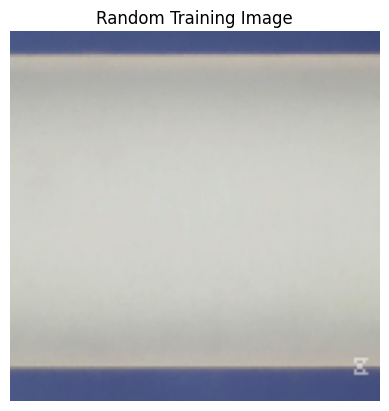

Grid label (Y[idx]):
[[[0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0.]]

 [[0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0.]]

 [[0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0.]]

 [[0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0.]
  [0. 0. 0. 0. 0.]]]


In [8]:
# Quick test on your training set (adjust paths as needed)
train_frames = '/content/clean_dataset/images'
train_labels = '/content/clean_dataset/labels'
X, Y = load_multi_boxes(train_frames, train_labels)
print("Image batch shape:", X.shape)
print("Label batch shape:", Y.shape)

# Show a random training image and its grid label as a matrix
import matplotlib.pyplot as plt
idx = np.random.randint(len(X))
plt.imshow((X[idx]*255).astype(np.uint8))
plt.title("Random Training Image")
plt.axis('off')
plt.show()
print("Grid label (Y[idx]):")
print(Y[idx])


In [9]:
from tensorflow.keras import layers, models, regularizers
import tensorflow as tf

# Fully convolutional YOLO-like head
input_shape = (IMG_SIZE, IMG_SIZE, 3)

def conv_block(x, filters, pool=True, sd=0.0):
    x = layers.Conv2D(filters, 3, padding='same',
                      kernel_initializer='he_normal',
                      kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    if sd > 0:
        x = layers.SpatialDropout2D(sd)(x)  # mild regularization
    if pool:
        x = layers.MaxPooling2D(2)(x)
    return x

inp = layers.Input(shape=input_shape)

# Downsample: 128→64→32→16→8→4 (matches GRID_SIZE=4)
x = conv_block(inp,  32, pool=True,  sd=0.05)
x = conv_block(x,    64, pool=True,  sd=0.05)
x = conv_block(x,   128, pool=True,  sd=0.05)
x = conv_block(x,   128, pool=True,  sd=0.05)
x = conv_block(x,   128, pool=True,  sd=0.05)

# Final prediction layer: 5 outputs per cell (obj, x, y, w, h)
out = layers.Conv2D(5, kernel_size=1, padding='same',
                    activation='linear',
                    kernel_regularizer=regularizers.l2(1e-4))(x)

model = models.Model(inputs=inp, outputs=out)

# Keep your original custom loss
def custom_loss(y_true, y_pred):
    obj_mask = y_true[..., 0]
    mask4 = tf.repeat(tf.expand_dims(obj_mask, -1), 4, axis=-1)
    box_loss = tf.reduce_sum(mask4 * tf.square(y_true[..., 1:] - y_pred[..., 1:]))
    obj_loss = tf.reduce_sum(tf.square(y_true[..., 0] - y_pred[..., 0]))
    return box_loss + obj_loss

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=custom_loss)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d               │ (None, 128, 128, 32)   │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_1             │ (None, 64, 64, 64)     │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_2             │ (None, 32, 32, 128)    │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_3             │ (None, 16, 16, 128)    │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 128)      │             

 Total params: 390,981 (1.49 MB)

 Trainable params: 390,021 (1.49 MB)

 Non-trainable params: 960 (3.75 KB)

In [10]:
# Check if the model runs on a dummy batch
dummy_x = np.random.rand(2, IMG_SIZE, IMG_SIZE, 3)
dummy_y = np.random.rand(2, GRID_SIZE, GRID_SIZE, 5)
model.train_on_batch(dummy_x, dummy_y)
print("Model runs on dummy data. Ready for real training.")


Model runs on dummy data. Ready for real training.


In [11]:
from sklearn.model_selection import train_test_split

# Split your actual loaded dataset
X_train, X_val, Y_train, Y_val = train_test_split(X, Y, test_size=0.2, random_state=42)

print(f"Train set: {X_train.shape[0]} samples, Val set: {X_val.shape[0]} samples")

history = model.fit(X_train, Y_train, epochs=25, batch_size=8, validation_data=(X_val, Y_val))


Train set: 1220 samples, Val set: 305 samples
Epoch 1/25
153/153 ━━━━━━━━━━━━━━━━━━━━ 68s 423ms/step - loss: 61.6757 - val_loss: 6.3196
Epoch 2/25
153/153 ━━━━━━━━━━━━━━━━━━━━ 83s 431ms/step - loss: 10.1789 - val_loss: 2.1717
Epoch 3/25
153/153 ━━━━━━━━━━━━━━━━━━━━ 64s 419ms/step - loss: 6.1402 - val_loss: 1.4207
Epoch 4/25
153/153 ━━━━━━━━━━━━━━━━━━━━ 81s 414ms/step - loss: 4.0259 - val_loss: 0.7262
Epoch 5/25
153/153 ━━━━━━━━━━━━━━━━━━━━ 85s 434ms/step - loss: 3.2141 - val_loss: 0.5161
Epoch 6/25
153/153 ━━━━━━━━━━━━━━━━━━━━ 84s 449ms/step - loss: 2.6160 - val_loss: 0.8464
Epoch 7/25
153/153 ━━━━━━━━━━━━━━━━━━━━ 81s 442ms/step - loss: 2.1660 - val_loss: 0.3989
Epoch 8/25
153/153 ━━━━━━━━━━━━━━━━━━━━ 81s 438ms/step - loss: 1.9161 - val_loss: 0.4632
Epoch 9/25
153/153 ━━━━━━━━━━━━━━━━━━━━ 79s 422ms/step - loss: 1.5974 - val_loss: 0.3658
Epoch 10/25
153/153 ━━━━━━━━━━━━━━━━━━━━ 85s 439ms/step - loss: 1.3065 - val_loss: 0.3580
Epoch 11/25
153/153 ━━━━━━━━━━━━━━━━━━━━ 81s 431ms/step - los

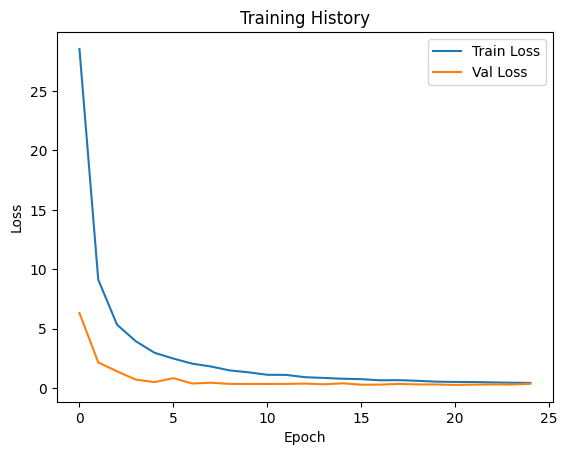

In [12]:
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Training History")
plt.show()


In [13]:
def predict_and_draw(model, img):
    img_resized = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    inp = np.expand_dims(img_resized/255.0, axis=0)
    pred = model.predict(inp)[0]
    img_disp = img_resized.copy()
    count = 0
    for y in range(GRID_SIZE):
        for x in range(GRID_SIZE):
            conf = pred[y, x, 0]
            if conf > 0.5:
                # 1. Decode normalized coords
                xc = (x + pred[y, x, 1]) / GRID_SIZE    # normalized
                yc = (y + pred[y, x, 2]) / GRID_SIZE
                w = pred[y, x, 3] / GRID_SIZE           # normalized
                h = pred[y, x, 4] / GRID_SIZE

                # 2. Scale to pixels
                px = int(xc * IMG_SIZE)
                py = int(yc * IMG_SIZE)
                pw = int(w * IMG_SIZE)
                ph = int(h * IMG_SIZE)

                # 3. Top-left and bottom-right
                x1, y1 = px - pw // 2, py - ph // 2
                x2, y2 = px + pw // 2, py + ph // 2

                cv2.rectangle(img_disp, (x1, y1), (x2, y2), (0,255,0), 2)
                count += 1
    plt.imshow(img_disp)
    plt.title(f"Detected microgels: {count}")
    plt.axis('off')
    plt.show()
    return count


True grid label (Y_val[idx]):
[[[0.        0.        0.        0.        0.       ]
  [0.        0.        0.        0.        0.       ]
  [0.        0.        0.        0.        0.       ]
  [0.        0.        0.        0.        0.       ]]

 [[0.        0.        0.        0.        0.       ]
  [0.        0.        0.        0.        0.       ]
  [1.        0.6947917 0.9574074 1.35      3.0222223]
  [0.        0.        0.        0.        0.       ]]

 [[0.        0.        0.        0.        0.       ]
  [0.        0.        0.        0.        0.       ]
  [0.        0.        0.        0.        0.       ]
  [0.        0.        0.        0.        0.       ]]

 [[0.        0.        0.        0.        0.       ]
  [0.        0.        0.        0.        0.       ]
  [0.        0.        0.        0.        0.       ]
  [0.        0.        0.        0.        0.       ]]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


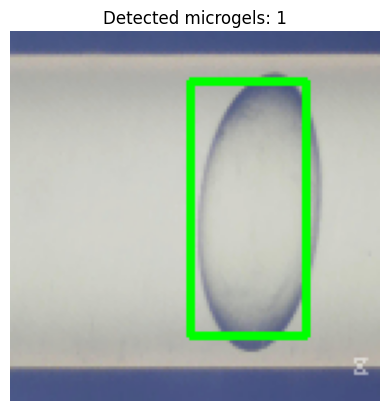

Counted microgels (predicted): 1


In [18]:
# Try on a validation image
idx = np.random.randint(len(X_val))
test_img = (X_val[idx]*255).astype(np.uint8)
print("True grid label (Y_val[idx]):")
print(Y_val[idx])
count = predict_and_draw(model, test_img)
print("Counted microgels (predicted):", count)


In [20]:
def count_microgels_in_folder(model, folder):
    files = sorted([f for f in os.listdir(folder) if f.lower().endswith(('.jpg', '.png'))])
    total_count = 0
    for f in files:
        img = cv2.imread(os.path.join(folder, f))
        c = predict_and_draw(model, img)
        total_count += c
    print(f"Total microgels detected in folder: {total_count}")


In [21]:
import random
import os
import cv2
import matplotlib.pyplot as plt

def sample_and_visualize(model, frame_folder, num_samples=5):
    # Get list of image files in the folder
    frame_files = sorted([f for f in os.listdir(frame_folder) if f.lower().endswith(('.jpg', '.png'))])
    if len(frame_files) < num_samples:
        print(f"Warning: Only {len(frame_files)} frames available.")
    # Randomly pick sample frames (no duplicates)
    chosen_files = random.sample(frame_files, min(len(frame_files), num_samples))
    print(f"Visualizing detections for frames: {chosen_files}")
    for fname in chosen_files:
        img_path = os.path.join(frame_folder, fname)
        img = cv2.imread(img_path)
        if img is None:
            print(f"Could not read {img_path}, skipping...")
            continue
        predict_and_draw(model, img)


Visualizing detections for frames: ['frame_01297.jpg', 'frame_00617.jpg', 'frame_00893.jpg', 'frame_01258.jpg', 'frame_00463.jpg']
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


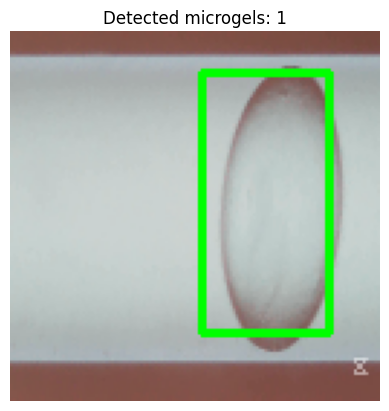

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


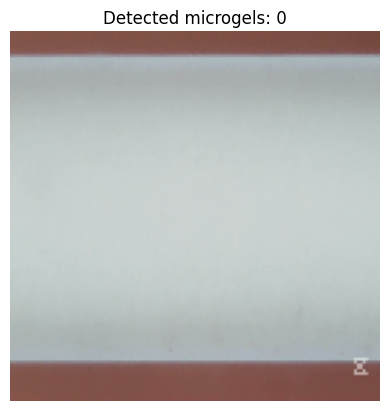

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


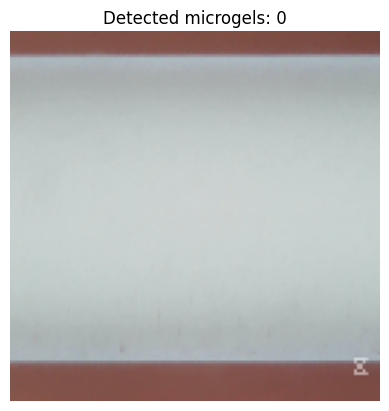

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


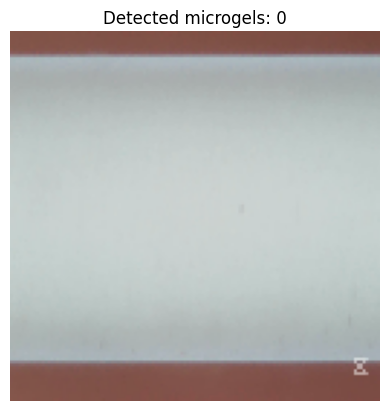

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


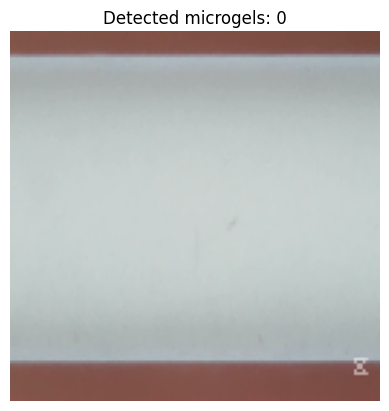

Visualizing detections for frames: ['frame_01896.jpg', 'frame_02387.jpg', 'frame_00783.jpg', 'frame_02431.jpg', 'frame_02270.jpg']
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


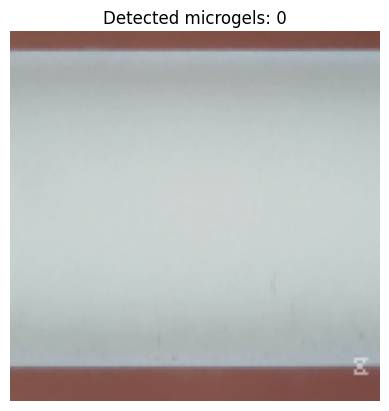

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


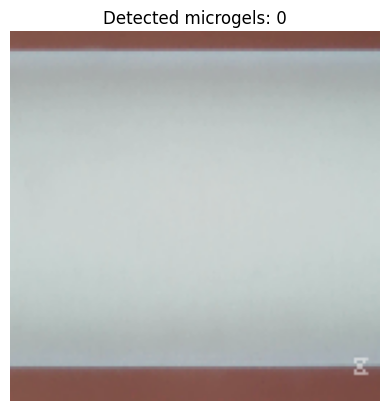

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


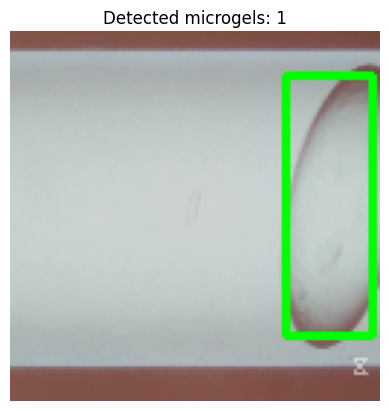

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


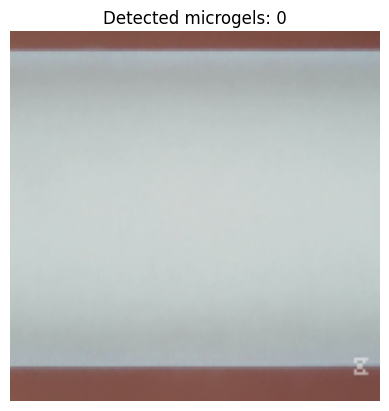

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


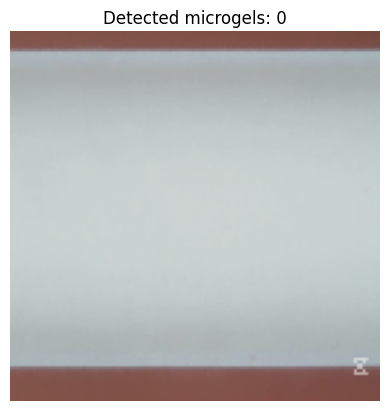

In [22]:
sample_and_visualize(model, '/content/Training_video_2')
sample_and_visualize(model, '/content/Training_video_3')


In [23]:
def count_microgels_in_video(model, frame_folder):
    files = sorted([f for f in os.listdir(frame_folder) if f.lower().endswith(('.jpg', '.png'))])
    total_count = 0
    for f in files:
        img = cv2.imread(os.path.join(frame_folder, f))
        if img is None:
            continue
        img_resized = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        inp = np.expand_dims(img_resized / 255.0, axis=0)
        pred = model.predict(inp)[0]
        count = 0
        for y in range(GRID_SIZE):
            for x in range(GRID_SIZE):
                conf = pred[y, x, 0]
                if conf > 0.5:
                    count += 1
        total_count += count
    print(f"Total microgels detected in '{frame_folder}': {total_count}")
    return total_count


In [24]:
def iou(boxA, boxB):
    # boxA and boxB format: [x1, y1, x2, y2] (pixel coordinates)
    xA = max(boxA[0], boxB[0])
    yA = max(boxA[1], boxB[1])
    xB = min(boxA[2], boxB[2])
    yB = min(boxA[3], boxB[3])

    interWidth = max(0, xB - xA)
    interHeight = max(0, yB - yA)
    interArea = interWidth * interHeight

    boxAArea = (boxA[2] - boxA[0]) * (boxA[3] - boxA[1])
    boxBArea = (boxB[2] - boxB[0]) * (boxB[3] - boxB[1])

    unionArea = boxAArea + boxBArea - interArea
    if unionArea == 0:
        return 0.0
    return interArea / unionArea


In [25]:
def decode_predictions(pred, conf_threshold=0.5):
    # pred shape: (GRID_SIZE, GRID_SIZE, 5)
    # returns list of boxes in pixel coordinates [x1, y1, x2, y2]
    boxes = []
    for y in range(GRID_SIZE):
        for x in range(GRID_SIZE):
            conf = pred[y, x, 0]
            if conf > conf_threshold:
                x_rel, y_rel = pred[y, x, 1], pred[y, x, 2]
                w_rel, h_rel = pred[y, x, 3], pred[y, x, 4]
                xc = (x + x_rel) / GRID_SIZE
                yc = (y + y_rel) / GRID_SIZE
                w = w_rel / GRID_SIZE
                h = h_rel / GRID_SIZE

                px = int(xc * IMG_SIZE)
                py = int(yc * IMG_SIZE)
                pw = int(w * IMG_SIZE)
                ph = int(h * IMG_SIZE)

                x1 = max(px - pw // 2, 0)
                y1 = max(py - ph // 2, 0)
                x2 = min(px + pw // 2, IMG_SIZE - 1)
                y2 = min(py + ph // 2, IMG_SIZE - 1)

                boxes.append([x1, y1, x2, y2])
    return boxes


In [26]:
def decode_ground_truth(label_grid):
    # label_grid shape: (GRID_SIZE, GRID_SIZE, 5)
    # Each cell: [objectness, x_rel, y_rel, w_rel, h_rel]
    gt_boxes = []
    for y in range(GRID_SIZE):
        for x in range(GRID_SIZE):
            obj = label_grid[y, x, 0]
            if obj == 1:
                x_rel = label_grid[y, x, 1]
                y_rel = label_grid[y, x, 2]
                w_rel = label_grid[y, x, 3]
                h_rel = label_grid[y, x, 4]

                xc = (x + x_rel) / GRID_SIZE
                yc = (y + y_rel) / GRID_SIZE
                w = w_rel / GRID_SIZE
                h = h_rel / GRID_SIZE

                px = int(xc * IMG_SIZE)
                py = int(yc * IMG_SIZE)
                pw = int(w * IMG_SIZE)
                ph = int(h * IMG_SIZE)

                x1 = max(px - pw // 2, 0)
                y1 = max(py - ph // 2, 0)
                x2 = min(px + pw // 2, IMG_SIZE - 1)
                y2 = min(py + ph // 2, IMG_SIZE - 1)

                gt_boxes.append([x1, y1, x2, y2])
    return gt_boxes


In [27]:
def evaluate_model(model, X_val, Y_val, iou_threshold=0.5, conf_threshold=0.5):
    TP, FP, FN = 0, 0, 0
    for i in range(len(X_val)):
        img = X_val[i]
        label_grid = Y_val[i]

        inp = np.expand_dims(img, axis=0)
        pred = model.predict(inp)[0]  # shape (GRID_SIZE, GRID_SIZE, 5)

        pred_boxes = decode_predictions(pred, conf_threshold)
        gt_boxes = decode_ground_truth(label_grid)

        matched_gt_indices = set()
        for pred_box in pred_boxes:
            ious = [iou(pred_box, gt_box) for gt_box in gt_boxes]
            max_iou = max(ious) if ious else 0
            max_iou_idx = ious.index(max_iou) if ious else -1

            if max_iou >= iou_threshold and max_iou_idx not in matched_gt_indices:
                TP += 1
                matched_gt_indices.add(max_iou_idx)
            else:
                FP += 1
        FN += (len(gt_boxes) - len(matched_gt_indices))

    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0

    print(f"Evaluation results:\nPrecision: {precision:.3f}\nRecall: {recall:.3f}\nF1 Score: {f1:.3f}")
    return precision, recall, f1


In [28]:
evaluate_model(model, X_val, Y_val)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━

(0.9591836734693877, 0.9591836734693877, 0.9591836734693877)

In [29]:
def count_microgels_cells(model, frame_folder, IMG_SIZE=128, GRID_SIZE=4, conf_th=0.50):
    files = sorted([f for f in os.listdir(frame_folder) if f.lower().endswith(('.jpg','.png'))])
    total = 0
    for f in files:
        img = cv2.imread(os.path.join(frame_folder, f))
        if img is None:
            continue
        pred = model.predict(np.expand_dims(cv2.resize(img, (IMG_SIZE, IMG_SIZE))/255.0, 0), verbose=0)[0]
        total += int((pred[...,0] > conf_th).sum())
    print(f"Frames: {len(files)} | Total microgels in '{frame_folder}': {total}")
    return total

# Example calls
video2 = "/content/Training_video_2"
video3 = "/content/Training_video_3"
total_v2 = count_microgels_cells(model, video2, IMG_SIZE=IMG_SIZE, GRID_SIZE=GRID_SIZE, conf_th=0.50)
total_v3 = count_microgels_cells(model, video3, IMG_SIZE=IMG_SIZE, GRID_SIZE=GRID_SIZE, conf_th=0.50)
print("Video 2 total:", total_v2)
print("Video 3 total:", total_v3)


Frames: 1322 | Total microgels in '/content/Training_video_2': 336
Frames: 2511 | Total microgels in '/content/Training_video_3': 645
Video 2 total: 336
Video 3 total: 645
